# Кластеризация: как найти группы без готовых ответов

Сегодня попробуем три способа искать группы: **KMeans**, **агломеративную кластеризацию** и **DBSCAN**. Наша цель - понять их идеи и научиться осмысленно читать результат. Запускать ячейки нужно сверху вниз.

Нужны `pandas`, `matplotlib`, `scikit-learn` и Jupyter. Набор Iris входит в `scikit-learn` и не требует скачивания. Источник: [документация load_iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html).

## 1. Подготовка

Импорты и функцию для рисунков оставляем готовыми: сегодня нас интересуют прежде всего данные и поведение алгоритмов. Функция `draw_clusters` показывает точки и подписывает цвета номером кластера. Номер - условное имя, а не оценка качества.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["axes.grid"] = True


def draw_clusters(points, labels, title, centers=None):
    labels = np.asarray(labels)
    fig, ax = plt.subplots()
    for label in np.unique(labels):
        mask = labels == label
        name = "шум (-1)" if label == -1 else f"кластер {label}"
        ax.scatter(points[mask, 0], points[mask, 1], label=name, alpha=0.8, s=40)
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=180,
                   c="black", label="центры")
    ax.set(xlabel="Длина лепестка (стандарт.)",
           ylabel="Ширина лепестка (стандарт.)", title=title)
    ax.legend()
    plt.show()

## 2. Знакомство с данными

Загрузите Iris. Посмотрите названия столбцов и первые пять строк. Затем оставьте только **длину и ширину лепестка** - два признака удобно показать на плоскости. Имена этих столбцов можно взять из списка `iris.feature_names[2:4]`.

Вопрос перед запуском: почему число вида (`target`) пока не должно попадать в `X`?

In [4]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
print(df.shape)
print(df.columns.tolist())
display(df.head())  # первые пять строк

feature_names = iris.feature_names[2:4]
X = df[feature_names]  # датафрейм из двух столбцов
print(X.describe())

(150, 5)
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


       petal length (cm)  petal width (cm)
count         150.000000        150.000000
mean            3.758000          1.199333
std             1.765298          0.762238
min             1.000000          0.100000
25%             1.600000          0.300000
50%             4.350000          1.300000
75%             5.100000          1.800000
max             6.900000          2.500000


Ответ: `target` хранит известный вид цветка, то есть правильный ответ. Кластеризация должна найти группы без подсказок. Если положить вид в `X`, алгоритм будет делить точки по готовой разметке, и проверять потом будет нечего. К тому же 0, 1 и 2 у вида это просто коды, расстояние между ними ничего не значит. Вид понадобится только в конце, чтобы сравнить с ним найденные кластеры.

Постройте диаграмму рассеяния двух выбранных признаков. Пока все точки одного цвета: меток групп у нас нет. Есть ли на глаз отдельная группа? Сколько ещё групп вы бы предположили?

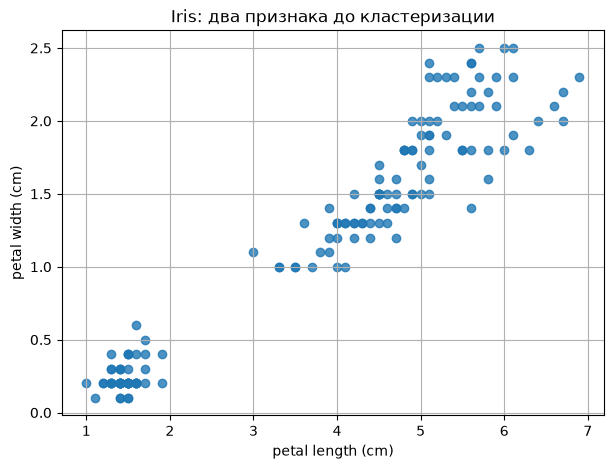

In [3]:
fig, ax = plt.subplots()
ax.scatter(X[feature_names[0]], X[feature_names[1]], alpha=0.8)
ax.set(xlabel=feature_names[0], ylabel=feature_names[1],
       title="Iris: два признака до кластеризации")
plt.show()

Ответ: да, одна группа видна сразу. Это точки в левом нижнем углу, у них короткие и узкие лепестки, и от остальных их отделяет заметный пустой промежуток. Остальные точки лежат одним вытянутым облаком. Я бы предположил в нём ещё две группы (поменьше и покрупнее), но на глаз границы между ними нет, точки идут сплошной полосой. Всего получается 2 или 3 группы.

Алгоритмы ниже работают с расстояниями. Поэтому приведём оба столбца к общему масштабу: после `StandardScaler` среднее каждого столбца около нуля, стандартное отклонение около единицы. Это не добавляет информации, но меняет единицы измерения. Сохраните результат в `X_scaled`; дальше все методы получат именно его.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # обучить scaler на X и преобразовать X
print(np.round(X_scaled.mean(axis=0), 2))
print(np.round(X_scaled.std(axis=0), 2))

[-0. -0.]
[1. 1.]


## 3. KMeans

Идея: заранее говорим, сколько групп хотим (`k`). Метод размещает `k` центров, относит каждую точку к ближайшему, пересчитывает центры и повторяет. Он **обязательно** назначает группу каждой точке. Число `random_state` делает результат повторяемым.

Создайте модель с тремя кластерами, получите метки и нарисуйте их вместе с центрами. Переменные ниже будут нужны и в следующих заданиях.

0    48
1    50
2    52
Name: count, dtype: int64


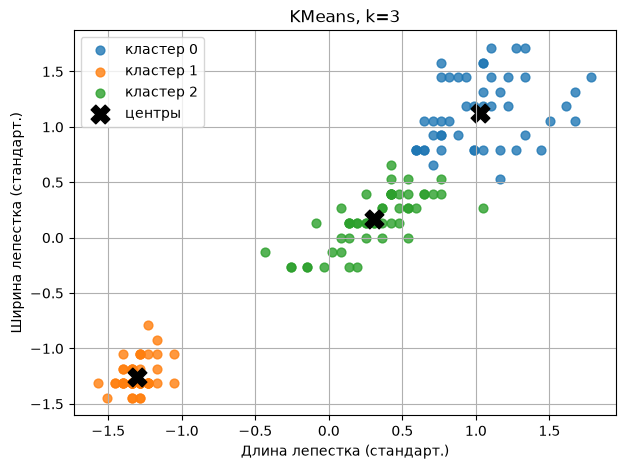

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)  # fit_predict на X_scaled
print(pd.Series(labels_kmeans).value_counts().sort_index())
draw_clusters(X_scaled, labels_kmeans, "KMeans, k=3",
              centers=kmeans.cluster_centers_)  # центры модели

Проверим, как выбор `k` влияет на результат. Для `k = 2, 3, 4` вычислите **силуэт**: значение ближе к 1 означает, что точки в среднем ближе к своей группе и дальше от соседней; около 0 - группы соприкасаются. Это подсказка, а не автоматический ответ. Силуэт определён только при числе групп от 2 до `n_samples - 1`.

Запишите: какое `k` получило наибольший силуэт? Значит ли это, что оно единственно правильное?

In [6]:
for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k}: силуэт={score:.3f}")

k=2: силуэт=0.743
k=3: силуэт=0.674
k=4: силуэт=0.599


Ответ: самый высокий силуэт у `k=2` (0.743). У `k=3` он 0.674, у `k=4` 0.599.

Это не значит, что правильный ответ два. Силуэт выше, когда группы плотные и далеко друг от друга. На двух признаках лепестка маленькое облако отделено хорошо, а остальная часть сплошная. Если объединить её в одну группу, силуэт вырастет, хотя по смыслу там могут быть две разные группы. Число `k` выбирают ещё и по задаче, по рисунку и по тому, можно ли объяснить найденные группы. Силуэт тут только одна из подсказок.

## 4. Агломеративная кластеризация

Здесь сначала каждая точка - отдельная группа. Затем ближайшие группы последовательно объединяются. Вариант `ward` старается не допустить большого разброса внутри новых групп. Зададим три итоговых кластера, чтобы сравнить с KMeans.

Получите метки, размеры групп и рисунок. Похожи ли границы на результат KMeans? Номера групп сравнивать напрямую нельзя: они произвольны.

0    75
1    50
2    25
Name: count, dtype: int64


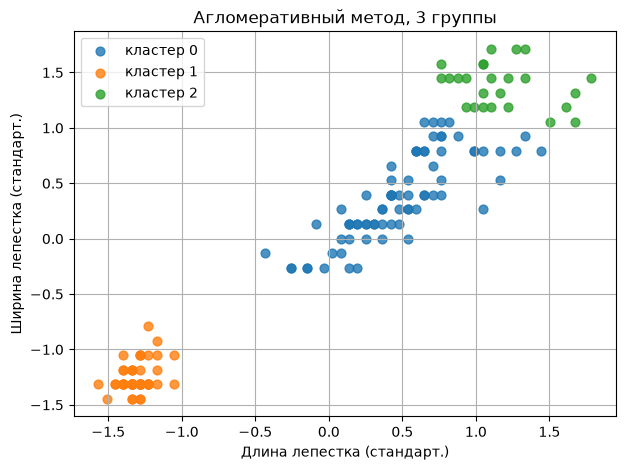

In [7]:
agglomerative = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_agg = agglomerative.fit_predict(X_scaled)
print(pd.Series(labels_agg).value_counts().sort_index())
draw_clusters(X_scaled, labels_agg, "Агломеративный метод, 3 группы")

Ответ: похожи только частично. Маленькая группа из 50 точек в левом нижнем углу совпадает с KMeans полностью. Большое облако методы режут по-разному. У KMeans получилось 52 и 48 точек, граница проходит примерно посередине. У агломеративного метода вышло 75 и 25: в отдельную группу ушёл только верхний правый край облака, а 23 точки, которые KMeans отнёс к верхней группе, попали в среднюю. Видно, что внутри сплошного облака граница сильно зависит от метода.

## 5. DBSCAN

DBSCAN ищет плотные области. `eps` - радиус соседства **в стандартизированных единицах**, `min_samples` - минимальное число точек в этом соседстве, включая саму точку. Метка `-1` означает шум: точка не попала ни в один найденный кластер. Число групп заранее не задаём.

Начните с `eps=0.25` и `min_samples=5`. Посчитайте группы и шум. Здесь ожидаются две группы и несколько точек с меткой `-1`: это не ошибка кода. Сравните рисунок с предыдущими.

-1     6
 0    50
 1    94
Name: count, dtype: int64


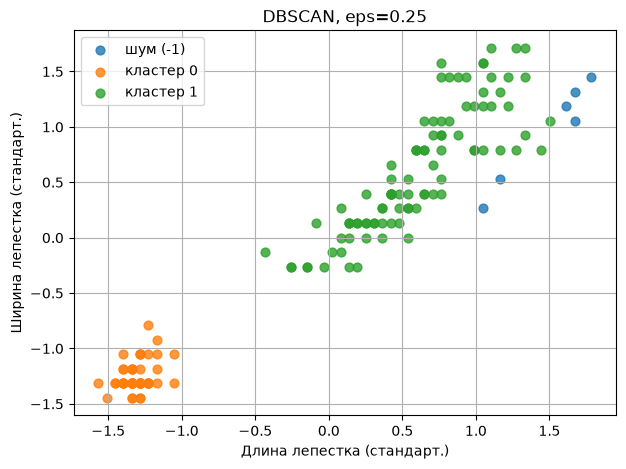

In [8]:
dbscan = DBSCAN(eps=0.25, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)
print(pd.Series(labels_dbscan).value_counts().sort_index())
draw_clusters(X_scaled, labels_dbscan, "DBSCAN, eps=0.25")

Ответ: DBSCAN нашёл две группы и 6 точек шума. Первая группа (50 точек) та же, что у двух прошлых методов. Вторая (94 точки) это всё большое облако целиком: между его частями нет пустого места, плотные соседи идут цепочкой, и метод не видит причины их делить. Шесть точек шума лежат справа, у длинных лепестков, где точки стоят реже. У них в радиусе 0.25 меньше пяти соседей, и ни к одной группе их не присоединили. KMeans и агломеративный метод распределяют все точки, поэтому у них шума нет.

Измените только `eps` на `0.35`. Сколько стало точек шума? Почему метод мог объединить группы или присоединить точки? Не подбирайте параметр по названиям видов: мы ещё не открывали ответы.

0     50
1    100
Name: count, dtype: int64


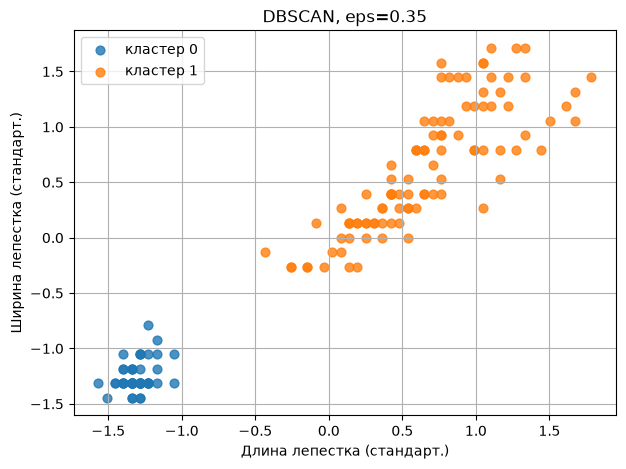

In [9]:
dbscan_wide = DBSCAN(eps=0.35, min_samples=5)
labels_dbscan_wide = dbscan_wide.fit_predict(X_scaled)
print(pd.Series(labels_dbscan_wide).value_counts().sort_index())
draw_clusters(X_scaled, labels_dbscan_wide, "DBSCAN, eps=0.35")

Ответ: точек шума не осталось (было 6, стало 0). Групп по-прежнему две, 50 и 100 точек.

С большим радиусом у каждой точки больше соседей. Редкие крайние точки теперь либо сами набирают пять соседей, либо оказываются рядом с плотной точкой кластера, и их присоединяют как граничные. Так же могут слиться и две группы: достаточно, чтобы между ними нашлась цепочка точек с шагом меньше `eps`. Здесь этого не случилось, промежуток до маленькой группы шире 0.35. При ещё большем `eps` метод в какой-то момент склеит всё в одну группу.

## 6. Сравнение

Составьте небольшую таблицу: метод, число найденных групп **без шума**, число шумовых точек. Для силуэта DBSCAN будем считать только точки, которым присвоена группа. Поэтому его оценка относится к меньшему набору строк и не является прямым соревнованием с остальными двумя значениями.

In [10]:
def summarize(name, labels, points):
    labels = np.asarray(labels)
    assigned = labels != -1
    n_clusters = len(np.unique(labels[assigned]))  # уникальные метки без -1
    n_noise = int((~assigned).sum())
    score = (silhouette_score(points[assigned], labels[assigned])
             if n_clusters >= 2 else np.nan)  # силуэт только для assigned, если групп хотя бы две
    return {"Метод": name, "Групп": n_clusters,
            "Шумовых точек": n_noise, "Силуэт*": score}


results = pd.DataFrame([
    summarize("KMeans", labels_kmeans, X_scaled),
    summarize("Агломеративный", labels_agg, X_scaled),
    summarize("DBSCAN (0.25)", labels_dbscan, X_scaled),
])
display(results)

,Метод,Групп,Шумовых точек,Силуэт*
0,KMeans,3,0,0.674131
1,Агломеративный,3,0,0.609944
2,DBSCAN (0.25),2,6,0.752324


Ответ: у KMeans и агломеративного метода по 3 группы и нет шума, силуэт 0.674 и 0.610. У DBSCAN (0.25) две группы и 6 шумовых точек, силуэт 0.752. Он самый высокий, но посчитан на 144 точках из 150 и для двух групп: трудные крайние точки выброшены, а сплошное облако не разделено. Поэтому сравнивать это число с двумя другими напрямую нельзя.

Только теперь посмотрим на известные виды Iris. Сделайте таблицу частот: строки - кластеры KMeans, столбцы - вид. Это не часть обучения модели. Кластер 0 не обязан означать вид 0; и биологические виды не обязаны выглядеть как три компактных облака на двух выбранных признаках.

In [11]:
comparison = pd.crosstab(
    pd.Series(labels_kmeans, name="Кластер KMeans"),
    pd.Series(iris.target_names[iris.target], name="Вид"),
)
display(comparison)  # comparison

Вид,setosa,versicolor,virginica
Кластер KMeans,,,
0,0,2,46
1,50,0,0
2,0,48,4


Ответ: кластер 1 KMeans совпал с видом setosa целиком, все 50 цветков. Кластер 2 в основном versicolor (48), к нему попали 4 virginica. Кластер 0 в основном virginica (46) и 2 versicolor. Всего 6 цветков из 150 оказались не в «своей» группе, и все они на стыке versicolor и virginica, где облака соприкасаются. Номера кластеров с номерами видов не совпадают, как и предупреждали.

## 7. Итог

Запишите 3–4 предложения своими словами:

1. Что у трёх методов общее?
2. Какую настройку нужно задать у KMeans и агломеративного метода, а какую - у DBSCAN?
3. Что означает метка `-1`? Почему силуэт сам по себе не доказывает, что группы «правильные»?
4. Для примера из транспорта - группировки остановок по пассажиропотоку и времени ожидания - какие дополнительные данные и проверки потребуются до управленческого решения?

**По желанию:** повторите опыт с двумя признаками чашелистика (`iris.feature_names[:2]`) и сравните рисунки. Не ожидайте тех же результатов: расстояния между точками изменятся.

Справка: [обзор методов кластеризации scikit-learn](https://scikit-learn.org/stable/modules/clustering.html), [silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

Ответ.

1. Все три метода ищут группы без меток и опираются на расстояния между точками. Поэтому им нужны признаки в одном масштабе, и результат у всех зависит от выбранных признаков и настроек.

2. У KMeans и агломеративного метода заранее задаётся число групп (`n_clusters`). У DBSCAN число групп не задаётся, вместо него нужны радиус соседства `eps` и минимальное число соседей `min_samples`.

3. Метка `-1` значит шум: у точки слишком мало соседей, и DBSCAN не отнёс её ни к одной группе. Силуэт показывает только геометрию, насколько группы плотные и разделённые. О смысле групп он ничего не говорит. В нашей работе самый высокий силуэт был у двух групп, а видов на самом деле три. Кроме того, у DBSCAN силуэт считается без шумовых точек и выглядит лучше, чем есть.

4. Для остановок одного пассажиропотока и времени ожидания мало. Нужны данные за разные дни недели, часы и сезоны, сведения о маршрутах и расписании, расположение остановок, что рядом (метро, торговые центры, больницы), и учёт пропусков в данных о валидациях. Проверить стоит, сохраняются ли группы на данных за другой период и при других `k` или `eps`, не являются ли «шумовые» остановки просто ошибками учёта. Ещё стоит показать группы диспетчерам и людям, которые знают сеть, а потом съездить на несколько остановок и проверить на месте. Решение лучше сначала опробовать на части сети и сравнить с тем, что было до изменений.

In [12]:
# По желанию: те же методы на двух признаках чашелистика
sepal_names = iris.feature_names[:2]
X_sepal = df[sepal_names]
X_sepal_scaled = StandardScaler().fit_transform(X_sepal)

for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_sepal_scaled)
    print(f"чашелистик, k={k}: силуэт={silhouette_score(X_sepal_scaled, labels):.3f}")

kmeans_sepal = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_kmeans_sepal = kmeans_sepal.fit_predict(X_sepal_scaled)
labels_agg_sepal = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_sepal_scaled)
labels_dbscan_sepal = DBSCAN(eps=0.25, min_samples=5).fit_predict(X_sepal_scaled)

display(pd.DataFrame([
    summarize("KMeans", labels_kmeans_sepal, X_sepal_scaled),
    summarize("Агломеративный", labels_agg_sepal, X_sepal_scaled),
    summarize("DBSCAN (0.25)", labels_dbscan_sepal, X_sepal_scaled),
]))


чашелистик, k=2: силуэт=0.448
чашелистик, k=3: силуэт=0.439
чашелистик, k=4: силуэт=0.408


,Метод,Групп,Шумовых точек,Силуэт*
0,KMeans,3,0,0.438871
1,Агломеративный,3,0,0.438600
2,DBSCAN (0.25),7,55,0.421952


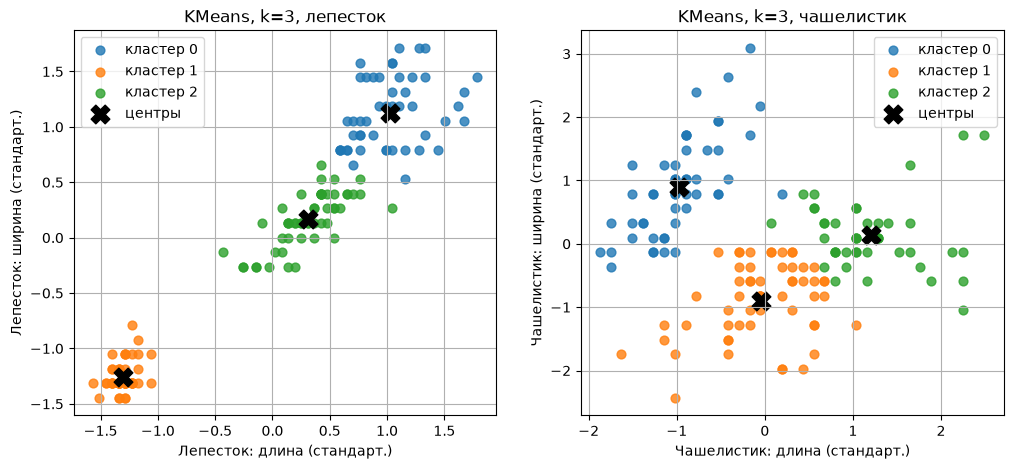

Вид,setosa,versicolor,virginica
Кластер KMeans (чашелистик),,,
0,49,1,0
1,1,36,20
2,0,13,30


In [13]:
# Рисунки рядом: KMeans, k=3 на лепестках и на чашелистиках.
# draw_clusters подписывает оси как лепесток, поэтому здесь рисуем сами.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pairs = [(X_scaled, labels_kmeans, kmeans, "Лепесток"),
         (X_sepal_scaled, labels_kmeans_sepal, kmeans_sepal, "Чашелистик")]
for ax, (points, labels, model, part) in zip(axes, pairs):
    for label in np.unique(labels):
        mask = labels == label
        ax.scatter(points[mask, 0], points[mask, 1], label=f"кластер {label}", alpha=0.8, s=40)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
               marker="X", s=180, c="black", label="центры")
    ax.set(xlabel=f"{part}: длина (стандарт.)", ylabel=f"{part}: ширина (стандарт.)",
           title=f"KMeans, k=3, {part.lower()}")
    ax.legend()
plt.show()

display(pd.crosstab(
    pd.Series(labels_kmeans_sepal, name="Кластер KMeans (чашелистик)"),
    pd.Series(iris.target_names[iris.target], name="Вид"),
))


Ответ: на чашелистике картина заметно хуже. Группа setosa всё ещё выделяется (кластер 0, в нём 49 из 50 setosa), но пустого промежутка вокруг неё больше нет, слева сверху она подходит к остальным точкам почти вплотную. Versicolor и virginica перемешаны: в кластере 1 их 36 и 20, в кластере 2 13 и 30. KMeans отнёс к чужой группе 35 цветков из 150, на лепестках таких было 6.

Силуэт тоже упал. При k=3 он 0.439, на лепестках был 0.674. При k=2, 3 и 4 значения почти одинаковые (между 0.41 и 0.45), то есть ни одно k не даёт чёткого разбиения. У агломеративного метода силуэт практически тот же, 0.439.

DBSCAN с eps=0.25 нашёл 7 мелких групп и записал в шум 55 точек. На чашелистике точки лежат реже, и радиус, подобранный для лепестков, здесь слишком мал. Его пришлось бы подбирать заново.

По двум признакам чашелистика виды различаются плохо, поэтому ни один из трёх методов не восстановит их так, как на лепестках. Результат кластеризации сильно зависит от того, какие признаки мы дали алгоритму.